# Neuro4ML - Week 2 - Synapses and networks

In this week's exercise you'll use different synapse models, excitation and inhibition, and network structure to design a neural network that can determine the temporal order of its inputs.

In [2]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

## Part 1 - Delays using biexponential synapses

In the cell below we check properties of the biexponential synapse that has equations:

$$\begin{aligned}
\tau \frac{dv}{dt} &= ax-v \\
\tau_x \frac{dx}{dt} &= -x
\end{aligned}$$

If we want to know the effect of an incoming spike that increases $x$ by 1, we can solve with initial conditions

$$\begin{aligned}
v(0) &= 0 \\
x(0) &= 1
\end{aligned}$$

We can see that we can solve for $x$ on its own to just get exponential decay so $x(t)=\exp(-t/\tau_x)$. Then we can just guess (by putting the equations into matrix vector form and noting the matrix is upper triangular and so the eigenvalues are just the diagonal elements) that $v(t)=A\cdot\exp(-t/\tau_x)+B\cdot\exp(-t/\tau)$ and substitute to get the solution:

$$\begin{aligned}
v(t) &= \frac{a\tau_x}{\tau-\tau_x}\left(e^{-t/\tau}-e^{-t/\tau_x}\right) \\
x(t) &= e^{-t/\tau_x}
\end{aligned}$$

Setting $v^\prime(t_0)=0$ and solving for $t_0$ to find the maximum we get

$$t_0 = \frac{\tau\tau_x}{\tau-\tau_x}\log\frac{\tau}{\tau_x}$$

and the maximum value is

$$v(t_0) = a\left(\frac{\tau}{\tau_x}\right)^{-\frac{\tau}{\tau-\tau_x}}$$

Note that we can choose to set $a=(\tau/\tau_x)^{\tau/(\tau-\tau_x)}$ if we want to normalise so that the maximum value $v(t_0)=1$.

### Task 1A

The code below solves this differential equation using Scipy's numerical ODE solver. Write your own code using Euler integration with a time step of ``dt`` and compare to the scipy solution. Compare to the analytic solution derived above.

Reminder: the Euler method for a differential equation $z^\prime=f(z)$ is:

$$z(t+\delta t)\approx z(t)+\delta t \cdot f(z)$$

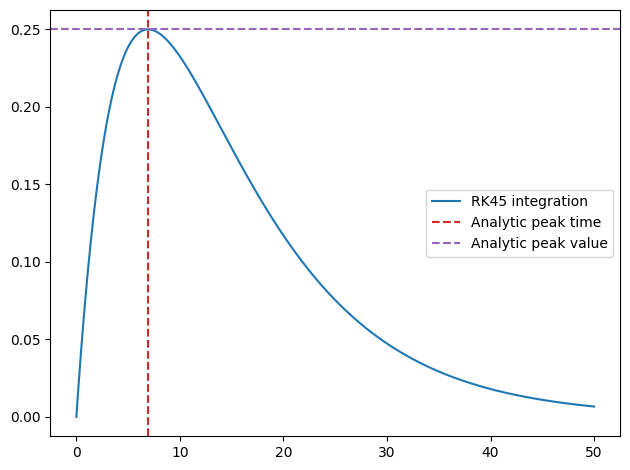

In [3]:
def plot_biexponential_psp(a, tau, taux):
    # differential equation in right form for scipy
    def f(t, z, a, tau, taux):
        v, x = z
        return [(a*x-v)/tau, -x/taux]
    # solution using scipy diffeq solver
    sol = solve_ivp(f, [0, 50], [0, 1], args=(a, tau, taux), max_step=0.1)
    plt.plot(sol.t, sol.y[0], label='RK45 integration')
    # analytic solution
    tmax = tau*taux/(tau-taux)*np.log(tau/taux)
    plt.axvline(tmax, ls='--', c='C3', label='Analytic peak time')
    plt.axhline(((taux/tau)**(tau/(tau-taux))), ls='--', c='C4', label='Analytic peak value')
    plt.legend(loc='best')
    plt.tight_layout()

plot_biexponential_psp(1, 10, 5)

dt=0.1: max |Euler - analytic| = 2.28e-03


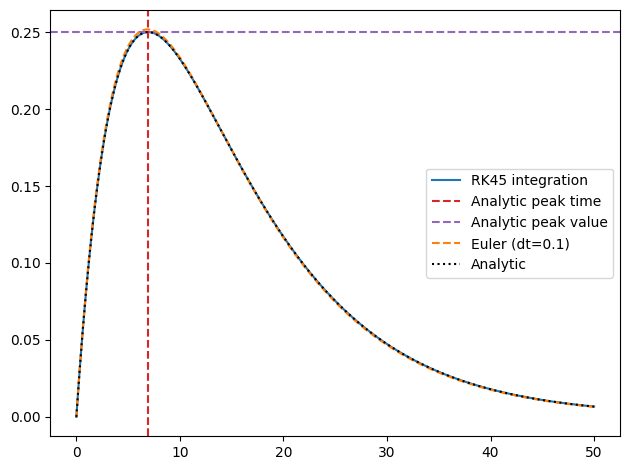

In [8]:
def plot_biexponential_euler(a, dt, T, tau, taux, compare=True):
  n = int(T/dt) # num steps = total time / step size
  t = np.arange(n+1)*dt
  v = np.zeros(n+1)
  x = np.zeros(n+1)

  # set starting values
  x[0] = 1
  v[0] = 0

  for i in range(n):
    dvdt = (a * x[i] - v[i]) / tau
    dxdt = -x[i] / taux
    v[i+1] = v[i] + dt * dvdt
    x[i+1] = x[i] + dt * dxdt

  if compare:
    plt.plot(t, v, '--', label=f'Euler (dt={dt})')
    # compare to analytic solution
    v_an = a*taux/(tau-taux) * (np.exp(-t/tau) - np.exp(-t/taux))
    plt.plot(t, v_an, ':k', label='Analytic')
    plt.legend()
    error = np.max(np.abs(v - v_an))
    print(f'dt={dt}: max |Euler - analytic| = {error:.2e}')
  else:
    plt.plot(t, v, label=f'τ={tau}, τx={taux}')

plot_biexponential_psp(1, 10, 5)
plot_biexponential_euler(1, 0.1, 50, 10, 5)

### Task 1B

Show the different range of delays you can get by varying $\tau$ in the range 1-9 ms and $\tau_x$ from 10-100 ms.

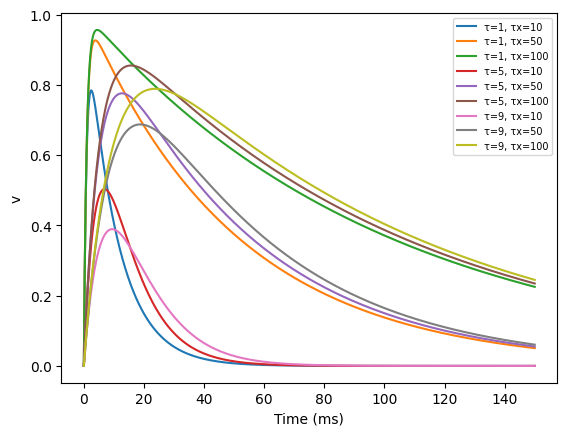

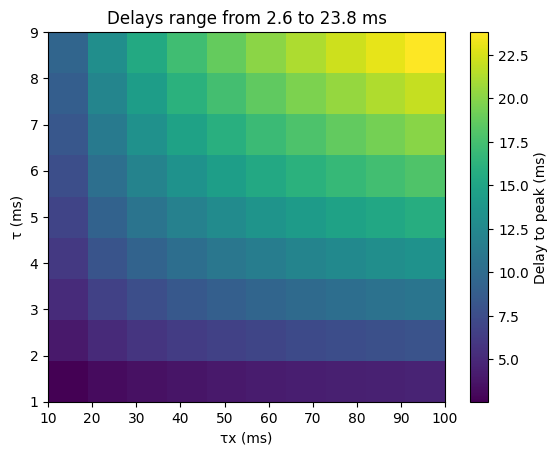

In [9]:
taus  = np.arange(1, 10)        # 1..9 ms
tauxs = np.arange(10, 101, 10)  # 10..100 ms

# Curves for a few combinations
plt.figure()
for tau in [1, 5, 9]:
    for taux in [10, 50, 100]:
        plot_biexponential_euler(1, 0.1, 150, tau, taux, compare=False)
plt.xlabel('Time (ms)'); plt.ylabel('v')
plt.legend(fontsize=7)
plt.show()

# Delay (peak time) for every combination
delays = np.zeros((len(taus), len(tauxs)))
for i, tau in enumerate(taus):
    for j, taux in enumerate(tauxs):
        delays[i, j] = tau*taux/(tau-taux) * np.log(tau/taux)

plt.figure()
plt.imshow(delays, origin='lower', aspect='auto',
           extent=[tauxs[0], tauxs[-1], taus[0], taus[-1]])
plt.colorbar(label='Delay to peak (ms)')
plt.xlabel('τx (ms)'); plt.ylabel('τ (ms)')
plt.title(f'Delays range from {delays.min():.1f} to {delays.max():.1f} ms')
plt.show()

### Task 1C

Write a simulator of $N$ neurons using this model, each of which receives a single input spike train at time 0, but with potentially different values of $\tau$ and $\tau_x$ for each neuron. Tune the parameters so that each neuron fires a single output spike with a different delay.

Use the template and test it using the code below to verify that you get similar results.

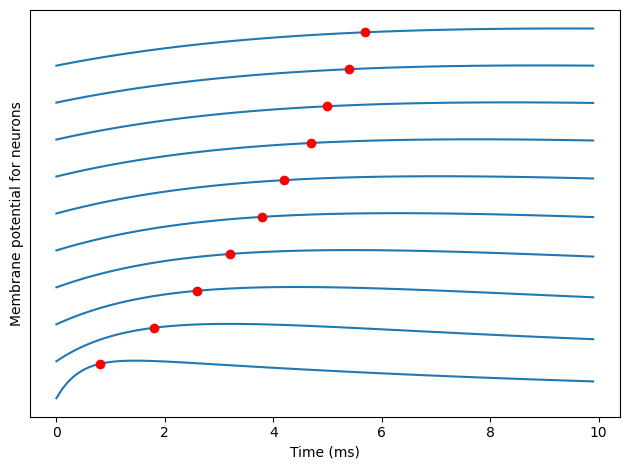

In [12]:
def simulate_biexponential_network(num_neurons, tau, taux, duration=10, dt=0.1, threshold=0.9):
    # state variables
    v = np.zeros(num_neurons)
    x = np.ones(num_neurons)          # every neuron gets an input spike at t=0
    # record activity
    num_time_steps = int(duration/dt)
    v_rec = np.zeros((num_neurons, num_time_steps))
    spike_time = np.zeros(num_neurons) # they will only fire one spike each

    # normalise so every neuron's v peaks at exactly 1
    a = (tau/taux)**(tau/(tau-taux))
    has_spiked = np.zeros(num_neurons, dtype=bool)

    # run simulation
    for step in range(num_time_steps):
        v_rec[:, step] = v

        # spike detection: crossed threshold and hasn't spiked yet
        crossed = (v > threshold) & ~has_spiked
        spike_time[crossed] = step*dt
        has_spiked[crossed] = True

        # Euler update (same as before, but for all neurons at once)
        dv = (a*x - v)/tau
        dx = -x/taux
        v = v + dt*dv
        x = x + dt*dx

    return v_rec, spike_time

taux = np.linspace(.5, 9, 10)
tau = 10
v, spike_times = simulate_biexponential_network(len(taux), tau, taux)
T = np.arange(v.shape[1])*0.1
for i in range(len(taux)):
    plt.plot(T, i+v[i, :], '-C0')
    plt.plot(spike_times[i], i+v[i, int(spike_times[i]/0.1)], 'or')
plt.xlabel('Time (ms)')
plt.ylabel('Membrane potential for neurons')
plt.yticks([])
plt.tight_layout();

notice how red dots become closer together with time, as tau is logarithmic

## Part 2 - Order sensitive network with lateral inhibition

In this part, we're going to create a network that takes two spike trains as input, one is delayed relative to the other with some delay, and can determine which spike train is delayed relative to which.

To start with, we'll use this function to generate these spike trains. It takes as an argument the number of time steps to generate, how many spikes there should be overall in each spike train, and a delay (in time steps). It returns an array ``spikes`` of shape ``(2, num_time_steps)`` of 0s and 1s (where 1 indicates a spike at that time). The delay can be positive or negative.

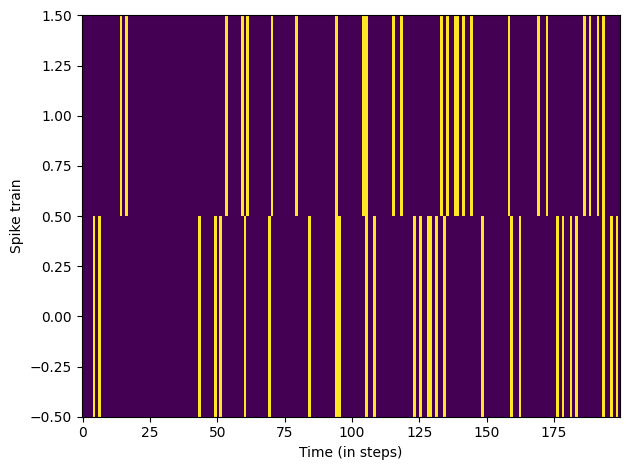

In [5]:
def create_spike_trains(num_time_steps, num_spikes_per_train, delay):
    max_delay_steps = abs(delay) # padding
    S = np.zeros((2, num_time_steps+2*abs(max_delay_steps))) # create two rows of 0s, with length num_time_steps apart with padding on both sides
    S[0, :num_spikes_per_train] = 1 # put 1s (spikes) in first num_spikes_per_train positions of row 0
    np.random.shuffle(S[0, :]) # shuffle these 1s so they scatter randomly
    S[1, max_delay_steps+delay:num_time_steps+delay+max_delay_steps] = S[0, max_delay_steps:num_time_steps+max_delay_steps] # row 1 copies row 0 but shifted + delay
    return S[:, max_delay_steps:num_time_steps+max_delay_steps]

plt.imshow(create_spike_trains(200, 30, 10), origin='lower', interpolation='nearest', aspect='auto')
plt.xlabel('Time (in steps)')
plt.ylabel('Spike train')
plt.tight_layout();

The order sensitive network looks like this:

![Order sensitive network](https://github.com/neuro4ml/exercises/blob/main/w2-synapses-networks/order-sensitive-network.png?raw=1)

Each output neuron receives an excitatory input from the input spike train with the same index, and an inhibitory input from the input spike train with the other index.

This means that if spike train 1 is a delayed version of spike train 0, then neuron 0 will first receive excitatory spikes then inhibitory spikes, allowing it to fire. However, neuron 1 will first receive inhibitory spikes and then excitatory spikes, meaning it won't fire. If on the other hand, spike train 0 is a delayed version of spike train 1, the opposite happens. So which neuron (index 0 or 1) fires a spike tells you the relative order of the input spike trains.

### Task 2

1. Implement this network with instantaneous excitatory and inhibitory synapses (cause an instant increase in $v$). Allow different excitatory and inhibitory weights.
2. Show with two input spike trains each consisting of just one spike that you can reproduce the figure above.
3. Show that using the spike train generator above that it works for sequences of spikes. Use a spike train of length 500 ms with 50 spikes and delays from -10 to +10 ms.

You can use the templates below to get started.

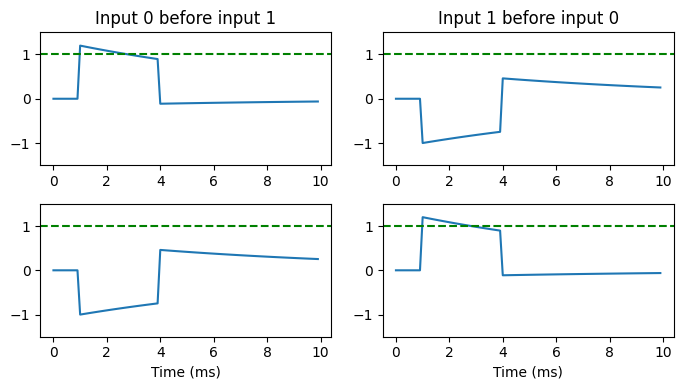

In [13]:
# vt is the spike threshold (we set it to a large value in the plotting code below to see what's going on)
def simulate_order_network(spikes, tau, we, wi, vt=1, dt=0.1):
    num_neurons = 2
    num_time_steps = spikes.shape[1]
    # state variables
    v = np.zeros(num_neurons)
    x = np.zeros(num_neurons)
    # record activity
    v_rec = np.zeros((num_neurons, num_time_steps))
    spike_count = np.zeros(num_neurons)
    # run simulation: FILL IN THE GAPS HERE
    for t in range(num_time_steps):
      v = v + dt * (-v / tau) # Euler method where dv/dt = -v/tau
      v = v + we * spikes[:, t] - wi * spikes[::-1, t]
      fired = v > vt # if pass threshold
      spike_count[fired] += 1 # count
      v[fired] = 0 # reset
      v_rec[:, t] = v
    return v_rec, spike_count

def plotit(order):
    dt = 0.1
    # Input data
    spikes = np.zeros((2, 100))
    spikes[order, 10] = spikes[1-order, 40] = 1
    # Model with threshold set to 10 so we can see traces without spikes
    v, spike_count = simulate_order_network(spikes, tau=10, we=1.2, wi=1, vt=10, dt=dt)
    # Plot
    T = np.arange(v.shape[1])*dt
    for i in range(2):
        plt.subplot(2, 2, 2*i+1+order)
        plt.plot(T, v[i, :])
        plt.axhline(1, ls='--', c='g')
        plt.ylim(-1.5, 1.5)
        if i:
            plt.xlabel('Time (ms)')
        else:
            plt.title(f'Input {order} before input {1-order}')

plt.figure(figsize=(7, 4))
plotit(0)
plotit(1)
plt.tight_layout();

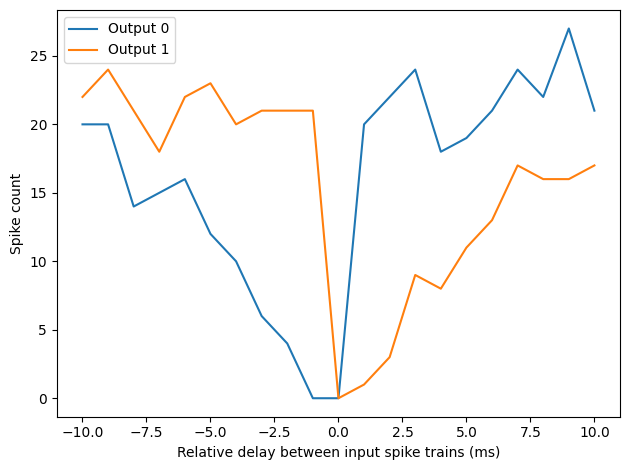

In [7]:
def order_spike_counts_simulation(d):
    # Input data
    num_time_steps, dt = 5000, 0.1 # 500 ms
    num_spikes = 50
    delay = int(d/dt)
    spikes = create_spike_trains(num_time_steps, num_spikes, delay)
    # Simulation
    v, spike_count = simulate_order_network(spikes, tau=10, we=1.2, wi=1, vt=1, dt=dt)
    return spike_count

D = np.arange(-10, 10+1)
C = [order_spike_counts_simulation(d) for d in D]
plt.plot(D, C, label=('Output 0', 'Output 1'))
plt.legend(loc='best')
plt.xlabel('Relative delay between input spike trains (ms)')
plt.ylabel('Spike count')
plt.tight_layout();


## Part 3 - Tuning the order-sensitive network with slow inhibition

Do the same as in the previous part, but this time make the inhibitory spikes act slowly by adding a biexponential synapse as in part 1. Keep the excitatory spikes instantaneous (they directly increase $v$).

What happens for different inhibitory time constants?

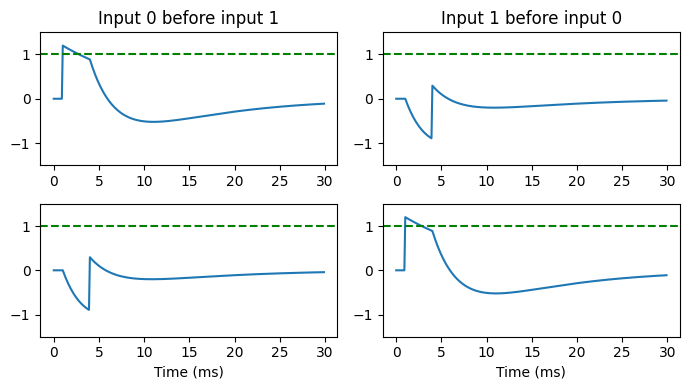

In [17]:
def simulate_order_network_slow(spikes, tau, taux, we, wi, vt=1, dt=0.1):
    num_neurons = 2
    num_time_steps = spikes.shape[1]
    # state variables
    v = np.zeros(num_neurons)
    x = np.zeros(num_neurons)   # inhibitory synapse variable
    # normalise so the inhibitory PSP peaks at wi (taux must not equal tau!)
    a = (tau/taux)**(tau/(tau-taux))
    # record activity
    v_rec = np.zeros((num_neurons, num_time_steps))
    spike_count = np.zeros(num_neurons)

    for t in range(num_time_steps):
        # Euler step for both equations
        dv = (-v - wi*a*x) / tau
        dx = -x / taux
        v = v + dt*dv
        x = x + dt*dx

        # excitation: instant jump in v from the same-index input
        v = v + we * spikes[:, t]
        # inhibition: kick x from the other-index input (slow effect on v)
        x = x + spikes[::-1, t]

        # threshold, count and reset
        fired = v > vt
        spike_count[fired] += 1
        v[fired] = 0
        v_rec[:, t] = v
    return v_rec, spike_count

def plotit_slow(order, taux):
    dt = 0.1
    spikes = np.zeros((2, 300))
    spikes[order, 10] = spikes[1-order, 40] = 1
    v, _ = simulate_order_network_slow(spikes, tau=10, taux=taux, we=1.2, wi=1, vt=10, dt=dt)
    T = np.arange(v.shape[1])*dt
    for i in range(2):
        plt.subplot(2, 2, 2*i+1+order)
        plt.plot(T, v[i, :])
        plt.axhline(1, ls='--', c='g')
        plt.ylim(-1.5, 1.5)
        if i:
            plt.xlabel('Time (ms)')
        else:
            plt.title(f'Input {order} before input {1-order}')

plt.figure(figsize=(7, 4))
plotit_slow(0, taux=3)
plotit_slow(1, taux=3)
plt.tight_layout();

## Part 4 - Cross-correlation network (optional extra)

Can you use the ideas here to build a network with more than two output that can accurately and robustly estimate the time delay between two spike trains? Robust means that it should have properties like:

* It should be invariant to the input spike count.
* It should work if there are additional noise spikes injected.
* It should work if some input spikes are randomly deleted.

What parameters determine performance and robustness?